# Bandit-Based Material Screening
**Project 5 · "25 Real-World RL Homework Projects (Unit 5)"**

## 1. Project title and original problem statement

**Professor's original problem statement (verbatim):**

> "A multi-armed or contextual bandit that chooses which candidate alloys or compounds to 'test' next from a public dataset (e.g., Matbench)."

**Deliverables covered by this notebook**
1. One-page problem formulation (state, action, reward, environment): Section 7.
2. Working implementation with standard bandit methods: Sections 8 to 11.
3. Learning curves against a baseline: Section 15.
4. Report and five slides are built from the results saved by this notebook (`results/` folder).


In [ ]:
PROFESSOR_STATEMENT = ("A multi-armed or contextual bandit that chooses which candidate alloys or compounds "
                       "to 'test' next from a public dataset (e.g., Matbench).")
print("Project 5: Bandit-Based Material Screening")
print("Original problem statement:\n ", PROFESSOR_STATEMENT)

Project 5: Bandit-Based Material Screening
Original problem statement:
  A multi-armed or contextual bandit that chooses which candidate alloys or compounds to 'test' next from a public dataset (e.g., Matbench).


## 2. Introduction and objectives

A materials researcher has a **fixed experimental budget** and a pool of candidate alloys. Every test costs time and money and returns a **noisy** measurement of the property of interest. The researcher must decide which alloy to test next. This is a multi-armed bandit: each alloy is an arm, each test is a pull.

**Primary target property: yield strength (MPa).** It is a real engineering objective (higher is better), continuous, positive, and available as a numerical label in the matminer steel strength data (the basis of the Matbench steels task). Tensile-test measurements are noisy, which justifies a stochastic reward.

**Objectives**
1. Build a simulated screening environment with hidden true material properties and noisy observations.
2. Implement Random, Epsilon-Greedy, UCB1 and Thompson Sampling with equal budgets.
3. Compare them over many seeds using cumulative reward, regret, best-material identification and discovery speed.
4. Document assumptions, limitations and ethics honestly, including which parts are real data and which are simulated.

In [ ]:
objectives = ["Simulated screening environment", "4 bandit algorithms, equal budget",
              "Multi-seed comparison with regret metrics", "Honest documentation of data and limits"]
for i, o in enumerate(objectives, 1):
    print(f"Objective {i}: {o}")

Objective 1: Simulated screening environment
Objective 2: 4 bandit algorithms, equal budget
Objective 3: Multi-seed comparison with regret metrics
Objective 4: Honest documentation of data and limits


## 3. Imports and configuration

Only `numpy`, `pandas` and `matplotlib` are used (all preinstalled on Colab). All experiment settings live in one `CONFIG` dictionary so every result is traceable to its settings.

The candidate pool is real data from the matminer `steel_strength` dataset. This needs internet access; the notebook installs `matminer` automatically if it is missing.

In [ ]:
import os, io, gzip, json, math, warnings, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

CONFIG = dict(
    N_ARMS      = 60,            # candidate materials in the pool
    BUDGET      = 300,           # number of experiments (horizon T)
    NOISE_SD    = 100.0,         # std of measurement noise in MPa (assumption)
    N_SEEDS     = 30,            # independent trials
    POOL_SEED   = 42,            # fixes the candidate pool
    EPSILON     = 0.1,           # Epsilon-Greedy exploration rate
    UCB_C       = 1.0,           # standard UCB1 (exploration scale)
    UCB_C_SMALL = 0.1,           # sensitivity variant (smaller bonus)
    PRIOR_MEAN  = 1000.0,        # Thompson prior mean (MPa)
    PRIOR_SD    = 500.0,         # Thompson prior std (MPa)
    R_MAX       = 2500.0,        # physical upper bound used to scale rewards to [0,1] for UCB1
    TOP_FRAC    = 0.10,          # "high-performing" = top 10% of the pool
)
os.makedirs("results", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})
print(json.dumps(CONFIG, indent=2))

{
  "N_ARMS": 60,
  "BUDGET": 300,
  "NOISE_SD": 100.0,
  "N_SEEDS": 30,
  "POOL_SEED": 42,
  "EPSILON": 0.1,
  "UCB_C": 1.0,
  "UCB_C_SMALL": 0.1,
  "PRIOR_MEAN": 1000.0,
  "PRIOR_SD": 500.0,
  "R_MAX": 2500.0,
  "TOP_FRAC": 0.1
}


## 4. Dataset loading and environment setup

**Dataset: matminer `steel_strength`.** 312 steels with composition and experimentally reported yield strength in MPa, distributed with the matminer package (Ward et al., 2018). The Matbench steels task (Dunn et al., 2020) is a benchmark of the same size. The loader below samples `N_ARMS` steels with a fixed seed. It needs internet access. The original source of the measurements is documented by matminer and Matbench; it is not verified here.

The pool values serve as the **hidden true mean performance** of each arm. Observations are simulated as true mean plus Gaussian noise (Section 6). With real data this means each reported strength is treated as the exact hidden mean, which is a modelling assumption: the dataset has no replicate measurements.

In [ ]:
def load_real_steels(n, seed):
    # REAL: matminer steel_strength (composition -> experimental yield strength, MPa)
    try:
        from matminer.datasets import load_dataset
    except ImportError:                      # install only when needed
        import subprocess, sys
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "matminer"])
        from matminer.datasets import load_dataset
    df = load_dataset("steel_strength")[["formula", "yield strength"]].copy()
    df.columns = ["material", "true_strength_MPa"]
    df["material"] = df["material"].astype(str)
    return df.sample(n=n, random_state=seed).reset_index(drop=True)

try:
    pool = load_real_steels(CONFIG["N_ARMS"], CONFIG["POOL_SEED"])
except Exception as e:
    raise RuntimeError("Could not load the matminer steel_strength dataset. Check the internet connection "
                       "and that matminer installed correctly (Runtime > Restart session, then Run all). "
                       f"Original error: {type(e).__name__}: {e}")
POOL_LABEL = "REAL: matminer steel_strength (experimental yield strength, MPa)"
print("Candidate pool source:", POOL_LABEL)
pool.head()

Fetching steel_strength.json.gz from https://ndownloader.figshare.com/files/13354691 to /usr/local/lib/python3.13/dist-packages/matminer/datasets/steel_strength.json.gz


Fetching https://ndownloader.figshare.com/files/13354691 in MB: 0.016384MB [00:00,  4.36MB/s]                 

Candidate pool source: REAL: matminer steel_strength (experimental yield strength, MPa)


,material,true_strength_MPa
0,Fe0.768C0.000931Mn0.00244Si0.00199Cr0.110Ni0.0...,1167.2
1,Fe0.648C0.00751Mn0.000103Si0.000201Cr0.158Ni0....,1502.0
2,Fe0.677C0.00916Mn0.000100Si0.0294Cr0.134Ni0.00...,1382.2
3,Fe0.679C0.00705Mn0.000103Si0.000201Cr0.153Ni0....,1341.7
4,Fe0.664C0.00926Mn0.000101Si0.0101Cr0.134Ni0.00...,1322.1


## 5. Data preprocessing and exploration

Preprocessing is minimal by design: check for missing values and duplicates, confirm units (MPa), and define the "high-performing" set (top 10% by true strength). The true strengths are used **only** by the environment and the evaluator, never by the agents.

Duplicates in material names: 0
Arms K=60 | best arm = Fe0.634C0.000478Mn0.000523Si0.00102Cr0.000111Ni0.173Mo0.0237V0.000113Nb0.0000619Co0.146Al0.00277Ti0.0176 (2487 MPa)
High-performing set: top 6 arms, threshold 1798 MPa
Gap between best and 2nd best (MPa): 330.0 | noise SD (MPa): 100.0


,count,mean,std,min,25%,50%,75%,max
true_strength_MPa,60.0,1408.7,268.8,1005.9,1230.2,1353.8,1510.6,2487.3


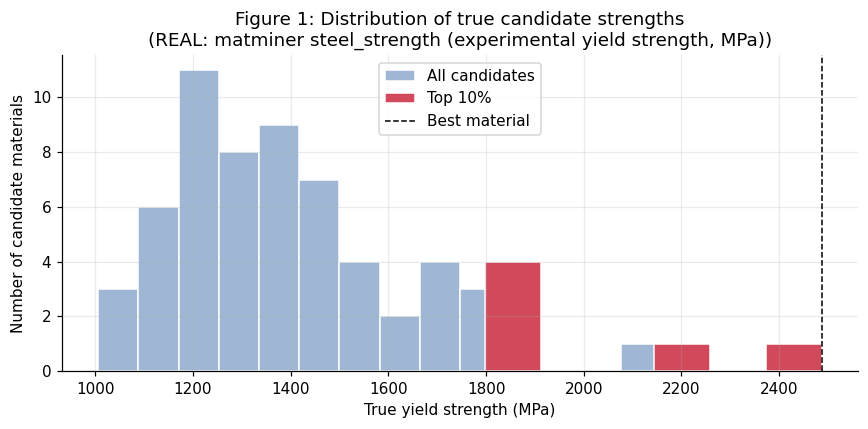

In [ ]:
assert pool["true_strength_MPa"].notna().all(), "missing targets"
print("Duplicates in material names:", pool["material"].duplicated().sum())
K = len(pool)
mu = pool["true_strength_MPa"].to_numpy(dtype=float)       # HIDDEN true mean per arm (MPa)
best_arm = int(np.argmax(mu)); mu_star = mu[best_arm]
n_top = int(math.ceil(CONFIG["TOP_FRAC"] * K))
top_set = np.argsort(-mu)[:n_top]                           # high-performing arms
print(f"Arms K={K} | best arm = {pool.material[best_arm]} ({mu_star:.0f} MPa)")
print(f"High-performing set: top {n_top} arms, threshold {mu[top_set].min():.0f} MPa")
print("Gap between best and 2nd best (MPa):", round(np.sort(mu)[-1] - np.sort(mu)[-2], 1),
      "| noise SD (MPa):", CONFIG["NOISE_SD"])
display(pool["true_strength_MPa"].describe().round(1).to_frame().T)

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(mu, bins=18, color="#9fb7d4", edgecolor="white", label="All candidates")
ax.hist(mu[top_set], bins=6, color="#d1495b", edgecolor="white", label=f"Top {int(CONFIG['TOP_FRAC']*100)}%")
ax.axvline(mu_star, color="k", ls="--", lw=1, label="Best material")
ax.set(title=f"Figure 1: Distribution of true candidate strengths\n({POOL_LABEL})",
       xlabel="True yield strength (MPa)", ylabel="Number of candidate materials")
ax.legend(); plt.tight_layout(); plt.savefig("results/fig1_distribution.png", dpi=150); plt.show()

## 6. Material-screening environment

**Reward model and assumptions**
- Each arm $a$ has an unknown true mean strength $\mu_a$ (hidden from agents).
- Testing arm $a$ for the $n$-th time returns an observation $r = \mu_a + \varepsilon$, with $\varepsilon \sim \mathcal{N}(0, \sigma^2)$ and $\sigma$ = `NOISE_SD`.
- Noise is independent across tests and the same for all arms (homoscedastic). This is an **assumption**: it mimics repeat-test scatter in tensile testing. It is not estimated from data.
- **No leakage:** the environment exposes only `step(arm)`, which returns a noisy value. The agent never sees $\mu$ before or after the pull.
- **Fair comparison:** for a given seed, the noise table is pre-drawn, so the $n$-th test of arm $a$ gets the same noise for every algorithm (common random numbers). Algorithms differ only through their choices.

The evaluator (not the agents) compares choices to the hidden truth.

In [ ]:
class MaterialScreeningEnv:
    # Hidden-truth simulator. Agents only call step(arm) and see a noisy reward in MPa.
    def __init__(self, true_means, noise_sd, horizon, seed):
        self._mu = np.asarray(true_means, dtype=float)              # private
        self.K = len(self._mu)
        rng = np.random.default_rng(seed)
        self._noise = rng.normal(0.0, noise_sd, size=(self.K, horizon))  # pre-drawn noise table
        self._pulls = np.zeros(self.K, dtype=int)
    def step(self, arm):
        n = self._pulls[arm]; self._pulls[arm] += 1
        return float(self._mu[arm] + self._noise[arm, n])           # observed reward

env_demo = MaterialScreeningEnv(mu, CONFIG["NOISE_SD"], CONFIG["BUDGET"], seed=0)
obs = [env_demo.step(best_arm) for _ in range(5)]
print("True mean of best arm:", round(mu_star, 1), "MPa")
print("5 noisy observations :", np.round(obs, 1), "(observed reward != true property)")

True mean of best arm: 2487.3 MPa
5 noisy observations : [2669.3 2421.7 2537.  2494.1 2673.3] (observed reward != true property)


## 7. Mathematical formulation (one-page problem formulation)

| Element | Definition |
|---|---|
| **Environment** | Pool of $K$ candidate alloys with hidden mean yield strengths $\mu_1,\dots,\mu_K$ (MPa). Noisy tests. |
| **State** | Stateless (multi-armed bandit). The agent's information state is the history $H_t=\{(a_s,r_s)\}_{s<t}$, summarised by counts $N_t(a)$ and sample means $\hat\mu_t(a)$. |
| **Action** | $a_t\in\{1,\dots,K\}$: which alloy to test next. |
| **Reward** | $r_t=\mu_{a_t}+\varepsilon_t$, $\varepsilon_t\sim\mathcal N(0,\sigma^2)$, in MPa. |
| **Horizon** | $T=300$ tests (the experimental budget). |
| **Objective** | Maximise $\sum_{t=1}^T r_t$, equivalently minimise cumulative regret $R_T=\sum_{t=1}^T(\mu^*-\mu_{a_t})$ with $\mu^*=\max_a\mu_a$. |

**Metrics.** Simple regret at time $t$: $\mu^*-\mu_{\hat a_t}$, where $\hat a_t=\arg\max_{a:N_t(a)>0}\hat\mu_t(a)$ is the material the agent would recommend after $t$ tests. Best-material identification: $\hat a_T=a^*$. Discovery time: first test of any top-10% alloy.

**Contextual extension (not implemented).** Material composition features could be used as context (e.g. LinUCB), which would help on a real pool with many arms. It is left as future work to keep the evaluation manageable and viva-friendly, as the assignment allows.

In [ ]:
spec = {"K (arms)": K, "Horizon T": CONFIG["BUDGET"], "Noise SD (MPa)": CONFIG["NOISE_SD"],
        "Best true mean mu* (MPa)": round(mu_star, 1), "Seeds": CONFIG["N_SEEDS"]}
for k, v in spec.items(): print(f"{k:28s}{v}")

K (arms)                    60
Horizon T                   300
Noise SD (MPa)              100.0
Best true mean mu* (MPa)    2487.3
Seeds                       30


## 8. Random baseline

**Principle.** Choose an arm uniformly at random: $P(a_t=a)=1/K$. It never uses past data, so it is pure exploration and its expected per-test reward equals the pool mean. It is the reference every learning algorithm must beat.

All agents share one interface: `select()` picks an arm, `update(arm, reward)` learns, `recommend()` returns the current best guess among tested arms. Agents receive **only** $K$, a random generator and hyperparameters. They are never given the true means.

In [ ]:
class BanditAgent:
    name = "base"
    def __init__(self, K, rng):
        self.K, self.rng = K, rng
        self.n = np.zeros(K, dtype=int)      # N(a): times arm a was tested
        self.Q = np.zeros(K)                 # running mean estimate of reward
        self.t = 0                           # tests so far
    def update(self, a, r):
        self.n[a] += 1; self.t += 1
        self.Q[a] += (r - self.Q[a]) / self.n[a]     # incremental mean: Q <- Q + (r-Q)/N
    def estimate(self):
        return np.where(self.n > 0, self.Q, -np.inf)
    def recommend(self):
        return int(np.argmax(self.estimate()))
    def _argmax_random_ties(self, v):
        m = np.flatnonzero(v == v.max()); return int(self.rng.choice(m))

class RandomAgent(BanditAgent):
    name = "Random"
    def select(self):
        return int(self.rng.integers(self.K))

## 9. Epsilon-Greedy implementation

**Principle.** With probability $1-\varepsilon$ test the arm with the highest estimated mean (exploit); with probability $\varepsilon$ test a random arm (explore).

**Update (incremental sample mean):**
$$N(a_t)\leftarrow N(a_t)+1,\qquad Q(a_t)\leftarrow Q(a_t)+\frac{r_t-Q(a_t)}{N(a_t)}$$

**Selection:** $a_t=\arg\max_a Q(a)$ w.p. $1-\varepsilon$, uniform otherwise. Implementation choice: every arm is tested once first (untried arms have $Q=+\infty$), the usual way to avoid committing to an arm that was never measured. Exploration stays constant at $\varepsilon$ forever, so some budget is always spent on random arms.

In [ ]:
class EpsilonGreedyAgent(BanditAgent):
    name = "Epsilon-Greedy"
    def __init__(self, K, rng, epsilon):
        super().__init__(K, rng); self.eps = epsilon
    def select(self):
        untried = np.flatnonzero(self.n == 0)
        if len(untried) > 0:                       # initial pass: test each arm once
            return int(self.rng.choice(untried))
        if self.rng.random() < self.eps:           # explore
            return int(self.rng.integers(self.K))
        return self._argmax_random_ties(self.Q)    # exploit

## 10. UCB1 implementation

**Principle.** Optimism in the face of uncertainty: pick the arm with the highest upper confidence bound on its mean. Rarely tested arms get a larger bonus, so exploration is driven by uncertainty and fades automatically as counts grow (Auer et al., 2002).

**Index (rewards scaled to $[0,1]$):**
$$a_t=\arg\max_a\left[\bar x(a)+c\sqrt{\frac{2\ln t}{N(a)}}\right]$$
Each arm is tested once first. Because UCB1 assumes rewards in $[0,1]$, observations are scaled as $x=\mathrm{clip}(r/R_{max},0,1)$ with a fixed physical bound $R_{max}=2500$ MPa (chosen from domain knowledge, not from the hidden pool). Standard UCB1 uses $c=1$. With a small noise-to-range ratio this bonus is large, so we also show a **sensitivity variant $c=0.1$**, labelled clearly as an extra.

In [ ]:
class UCB1Agent(BanditAgent):
    def __init__(self, K, rng, c, r_max, label):
        super().__init__(K, rng); self.c, self.r_max, self.name = c, r_max, label
    def update(self, a, r):
        super().update(a, float(np.clip(r / self.r_max, 0.0, 1.0)))   # Q holds scaled reward
    def select(self):
        untried = np.flatnonzero(self.n == 0)
        if len(untried) > 0:
            return int(untried[0])
        bonus = self.c * np.sqrt(2.0 * np.log(self.t) / self.n)
        return self._argmax_random_ties(self.Q + bonus)

## 11. Thompson Sampling implementation

**Principle.** Keep a posterior belief over each arm's mean, draw one sample from each posterior, and test the arm with the largest sample. Uncertain arms are tested often enough because their wide posteriors sometimes produce high samples; exploration shrinks as posteriors tighten (Thompson, 1933; Russo et al., 2018).

**Model.** Gaussian rewards with known noise $\sigma^2$ and prior $\mu_a\sim\mathcal N(m_0,\tau_0^2)$. After $N$ tests with reward sum $S$, the posterior is Gaussian:
$$\lambda=\frac1{\tau_0^2}+\frac N{\sigma^2},\qquad m=\frac{m_0/\tau_0^2+S/\sigma^2}{\lambda},\qquad \mu_a\mid H\sim\mathcal N\!\left(m,\;1/\lambda\right)$$
**Selection:** draw $\tilde\mu_a\sim\mathcal N(m_a,1/\lambda_a)$ for every arm, play $\arg\max_a\tilde\mu_a$. Assumption: the agent knows $\sigma$ (the lab's repeat-test scatter) and uses a broad prior $m_0=1000$, $\tau_0=500$ MPa, neither taken from the hidden pool.

In [ ]:
class ThompsonAgent(BanditAgent):
    name = "Thompson Sampling"
    def __init__(self, K, rng, prior_mean, prior_sd, noise_sd):
        super().__init__(K, rng)
        self.m0, self.prec0, self.noise_var = prior_mean, 1.0 / prior_sd**2, noise_sd**2
        self.S = np.zeros(K)                       # sum of rewards per arm
    def update(self, a, r):
        super().update(a, r); self.S[a] += r
    def posterior(self):
        prec = self.prec0 + self.n / self.noise_var
        mean = (self.m0 * self.prec0 + self.S / self.noise_var) / prec
        return mean, prec
    def select(self):
        mean, prec = self.posterior()
        sample = mean + self.rng.standard_normal(self.K) / np.sqrt(prec)
        return self._argmax_random_ties(sample)
    def estimate(self):                            # recommendation: best posterior mean among tested arms
        mean, _ = self.posterior()
        return np.where(self.n > 0, mean, -np.inf)

## 12. Experimental execution

The runner is separate from evaluation. `run_one` only records what the agent did (arms, observed rewards, recommendation after each test, and whether the pull matched the agent's greedy choice). It never touches the true means. Evaluation happens afterwards in Section 14.

All algorithms use the same budget $T$, the same pool, and (per seed) the same noise table.

In [ ]:
T, NS = CONFIG["BUDGET"], CONFIG["N_SEEDS"]
ALGOS = {   # name -> factory(rng); agents get hyperparameters only, never the true means
    "Random":            lambda rng: RandomAgent(K, rng),
    "Epsilon-Greedy":    lambda rng: EpsilonGreedyAgent(K, rng, CONFIG["EPSILON"]),
    "UCB1":              lambda rng: UCB1Agent(K, rng, CONFIG["UCB_C"], CONFIG["R_MAX"], "UCB1"),
    "Thompson Sampling": lambda rng: ThompsonAgent(K, rng, CONFIG["PRIOR_MEAN"], CONFIG["PRIOR_SD"], CONFIG["NOISE_SD"]),
    "UCB1 (c=0.1)":      lambda rng: UCB1Agent(K, rng, CONFIG["UCB_C_SMALL"], CONFIG["R_MAX"], "UCB1 (c=0.1)"),
}
CORE = ["Random", "Epsilon-Greedy", "UCB1", "Thompson Sampling"]   # the four required algorithms
COLORS = {"Random": "#7f7f7f", "Epsilon-Greedy": "#e69f00", "UCB1": "#0072b2",
          "Thompson Sampling": "#009e73", "UCB1 (c=0.1)": "#cc79a7"}

def run_one(name, seed):
    algo_id = list(ALGOS).index(name)
    rng = np.random.default_rng(np.random.SeedSequence([seed, algo_id]))
    env = MaterialScreeningEnv(mu, CONFIG["NOISE_SD"], T, seed)          # same noise for all algos
    agent = ALGOS[name](rng)
    arms = np.zeros(T, int); rew = np.zeros(T); recs = np.zeros(T, int); greedy = np.zeros(T, bool)
    for t in range(T):
        g = agent.recommend() if t > 0 else -1       # greedy choice BEFORE this test
        a = agent.select()
        r = env.step(a)                              # noisy observation only
        agent.update(a, r)
        arms[t], rew[t], recs[t], greedy[t] = a, r, agent.recommend(), (a == g)
    return dict(arms=arms, rew=rew, recs=recs, greedy=greedy, counts=agent.n.copy())

run_one("Thompson Sampling", 0)          # quick smoke test
print("Single run OK. Example (seed 0): first 10 arms tested by Thompson Sampling:",
      run_one("Thompson Sampling", 0)["arms"][:10])

Single run OK. Example (seed 0): first 10 arms tested by Thompson Sampling: [23  5  7  6 10 38 20  2 56  9]


## 13. Multiple-seed evaluation

Every algorithm is run on seeds $0,\dots,29$ (30 independent trials) with the identical candidate pool. Seeds change the noise and the algorithms' own randomness only.

In [ ]:
RUNS = {name: [run_one(name, s) for s in range(NS)] for name in ALGOS}
print({n: len(v) for n, v in RUNS.items()}, "runs each,", T, "tests per run")

{'Random': 30, 'Epsilon-Greedy': 30, 'UCB1': 30, 'Thompson Sampling': 30, 'UCB1 (c=0.1)': 30} runs each, 300 tests per run


## 14. Performance metrics

Evaluation compares each run to the **hidden truth** $\mu$. Reward columns are *observed* (noisy) MPa. Regret columns use the *true* underlying strengths.

- Cumulative reward and average reward per test: from observed rewards.
- Cumulative regret: $\sum_t(\mu^*-\mu_{a_t})$ (true means of chosen arms).
- Simple regret: $\mu^*-\mu_{\hat a_t}$ for the recommended arm.
- Best-material identification: recommended arm at $T$ equals the true best arm.
- Discovery time: first test of a top-10% arm.
- Exploitation share: fraction of tests that matched the agent's greedy choice (the rest are exploratory).

In [ ]:
def evaluate(run):
    arms, rew, recs = run["arms"], run["rew"], run["recs"]
    first_visit = np.zeros(T, bool); seen = set()
    for i, a in enumerate(arms):
        if a not in seen: first_visit[i] = True; seen.add(a)
    in_top = np.isin(arms, top_set)
    return dict(
        cum_reward = np.cumsum(rew),
        avg_reward = np.cumsum(rew) / np.arange(1, T + 1),
        cum_regret = np.cumsum(mu_star - mu[arms]),
        simple_regret = mu_star - mu[recs],
        best_found = (recs == best_arm).astype(float),
        unique_arms = np.cumsum(first_visit),
        top_discovered = np.maximum.accumulate(in_top).astype(float),
        discovery_step = (int(np.argmax(in_top)) + 1) if in_top.any() else T + 1,
        top_pull_frac = in_top.astype(float),
        greedy = run["greedy"].astype(float),
    )

EV = {name: [evaluate(r) for r in runs] for name, runs in RUNS.items()}
def stack(name, key): return np.array([e[key] for e in EV[name]])   # shape (seeds, T)

def ci95(x, axis=0):
    return 1.96 * np.std(x, axis=axis, ddof=1) / np.sqrt(x.shape[axis])

rows = []
for name in ALGOS:
    cr, ar, rg = stack(name, "cum_reward"), stack(name, "avg_reward"), stack(name, "cum_regret")
    sr, bf = stack(name, "simple_regret"), stack(name, "best_found")
    ds = np.array([e["discovery_step"] for e in EV[name]])
    rows.append({
        "Algorithm": name,
        "Cumulative reward (MPa)": f"{cr[:, -1].mean():,.0f} ± {ci95(cr[:, -1]):.0f}",
        "Avg reward/test (MPa)": f"{ar[:, -1].mean():.1f}",
        "Cumulative regret (MPa)": f"{rg[:, -1].mean():,.0f} ± {ci95(rg[:, -1]):.0f}",
        "Final simple regret (MPa)": f"{sr[:, -1].mean():.1f} ± {ci95(sr[:, -1]):.1f}",
        "Best-material ID (%)": f"{100 * bf[:, -1].mean():.0f}",
        "Median tests to first top-10% hit": f"{np.median(ds):.0f}",
        "Distinct materials tested": f"{stack(name, 'unique_arms')[:, -1].mean():.1f}",
        "Top-10% share, last 100 tests (%)": f"{100 * stack(name, 'top_pull_frac')[:, -100:].mean():.1f}",
        "Greedy-choice share (%)": f"{100 * stack(name, 'greedy')[:, 1:].mean():.1f}",
    })
summary = pd.DataFrame(rows).set_index("Algorithm")
display(summary.T)

# paired differences vs Random (same seeds, same noise)
paired = {}
for name in ALGOS:
    if name == "Random": continue
    d = stack(name, "cum_reward")[:, -1] - stack("Random", "cum_reward")[:, -1]
    paired[name] = (d.mean(), ci95(d))
print("\nPaired gain in cumulative reward vs Random (MPa, mean ± 95% CI):")
for k, (m, c) in paired.items(): print(f"  {k:18s}{m:9,.0f} ± {c:,.0f}")

Algorithm,Random,Epsilon-Greedy,UCB1,Thompson Sampling,UCB1 (c=0.1)
Cumulative reward (MPa),"422,827 ± 2007","656,257 ± 1562","434,094 ± 652","685,205 ± 13991","673,483 ± 860"
Avg reward/test (MPa),1409.4,2187.5,1447.0,2284.0,2244.9
Cumulative regret (MPa),"323,156 ± 1824","89,898 ± 1401","312,026 ± 227","60,954 ± 13795","72,594 ± 504"
Final simple regret (MPa),0.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0,22.0 ± 30.0,0.0 ± 0.0
Best-material ID (%),100,100,100,93,100
Median tests to first top-10% hit,7,8,22,6,22
Distinct materials tested,59.6,60.0,60.0,39.5,60.0
"Top-10% share, last 100 tests (%)",10.3,91.4,13.7,96.8,98.3
Greedy-choice share (%),1.8,72.6,2.6,86.6,75.7



Paired gain in cumulative reward vs Random (MPa, mean ± 95% CI):
  Epsilon-Greedy      233,430 ± 2,359
  UCB1                 11,267 ± 1,914
  Thompson Sampling   262,378 ± 15,063
  UCB1 (c=0.1)        250,656 ± 2,160


## 15. Visualization and comparisons

All figures are computed from the runs above (mean over 30 seeds, shaded band = 95% confidence interval across seeds). Figure 1 is in Section 5.

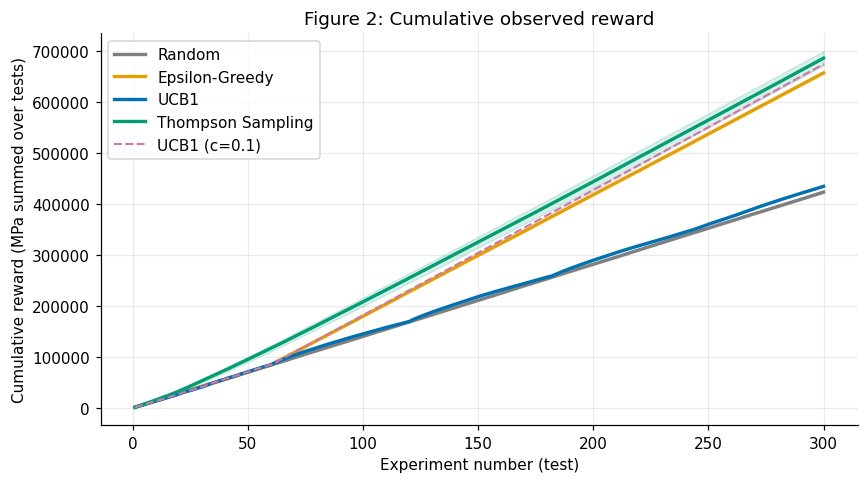

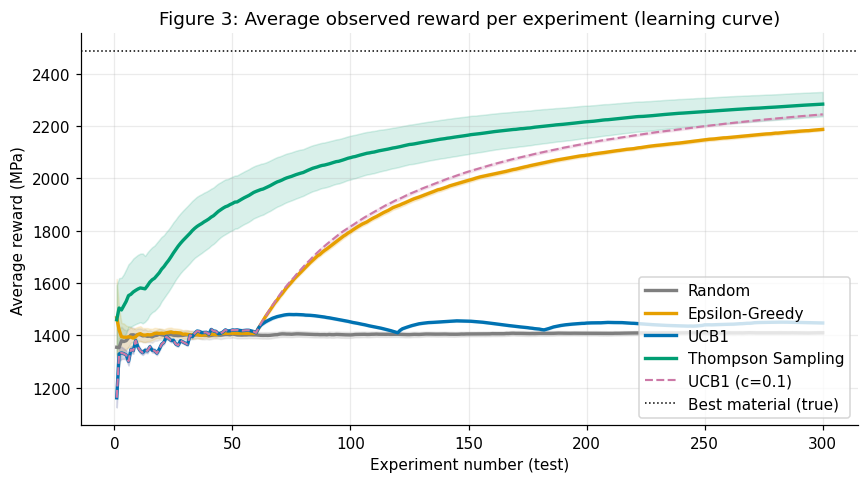

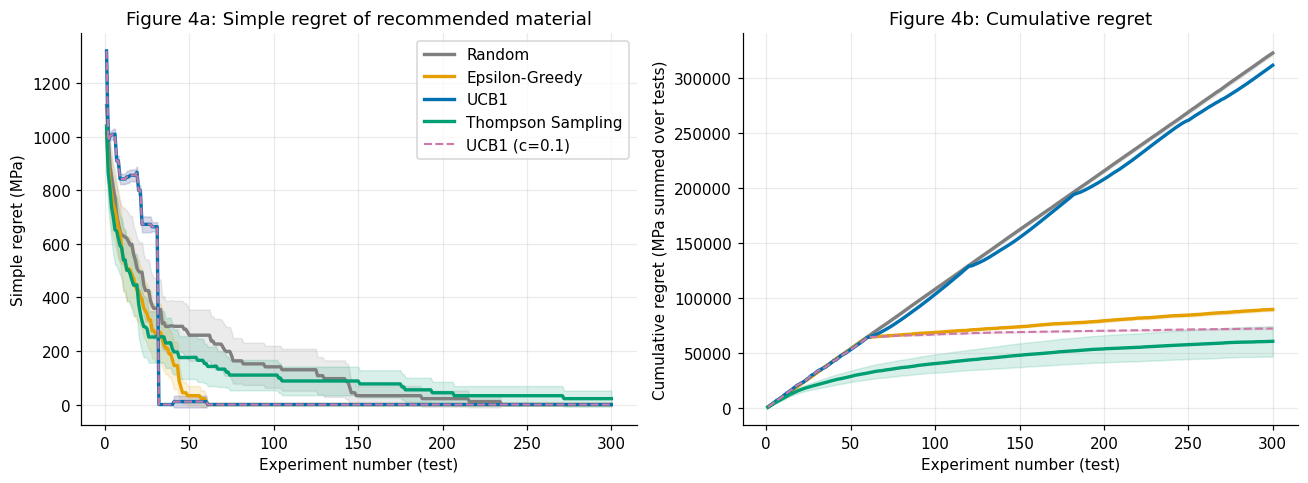

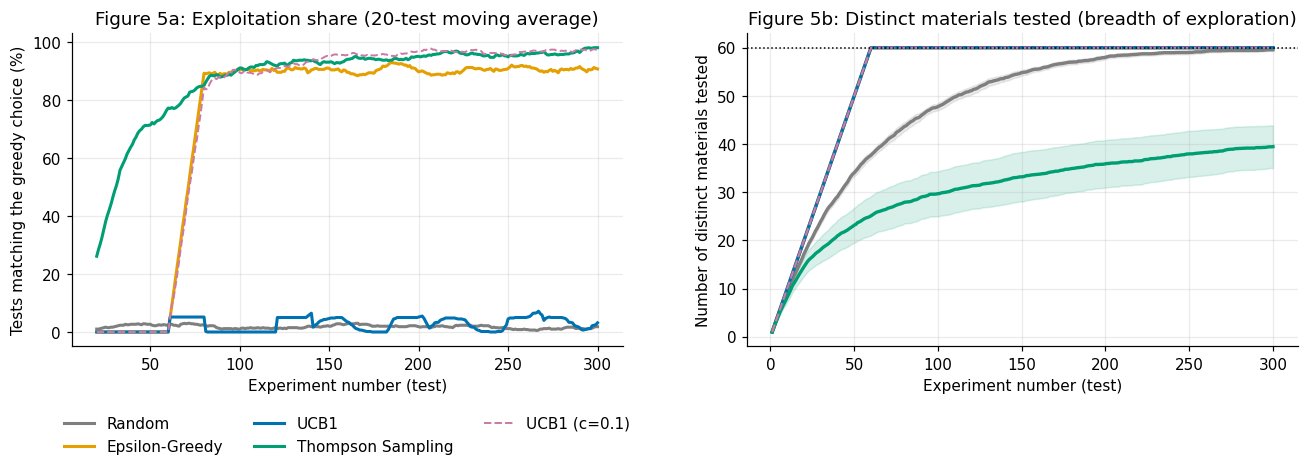

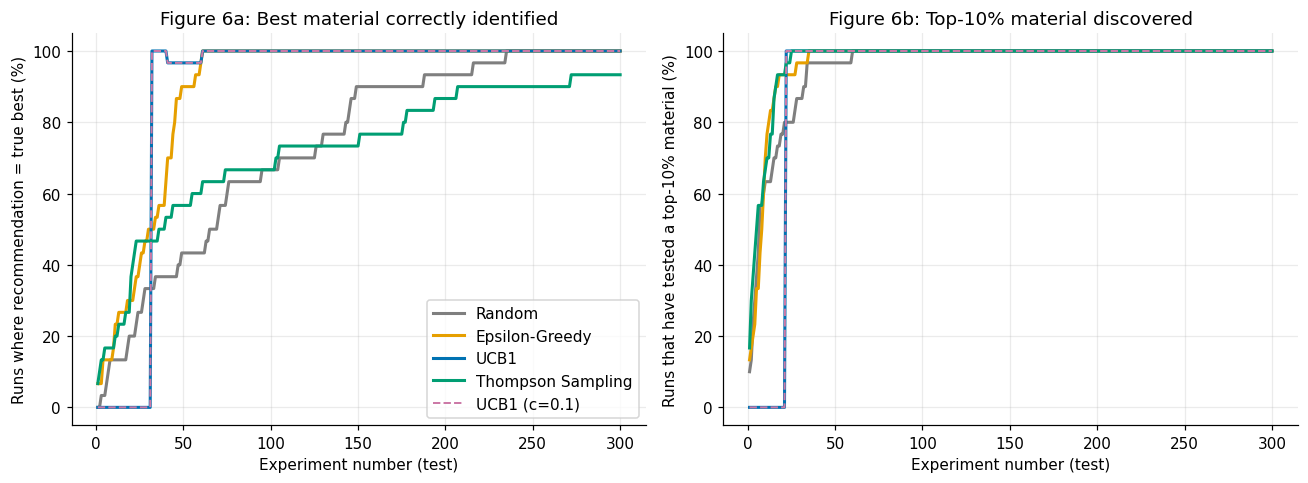

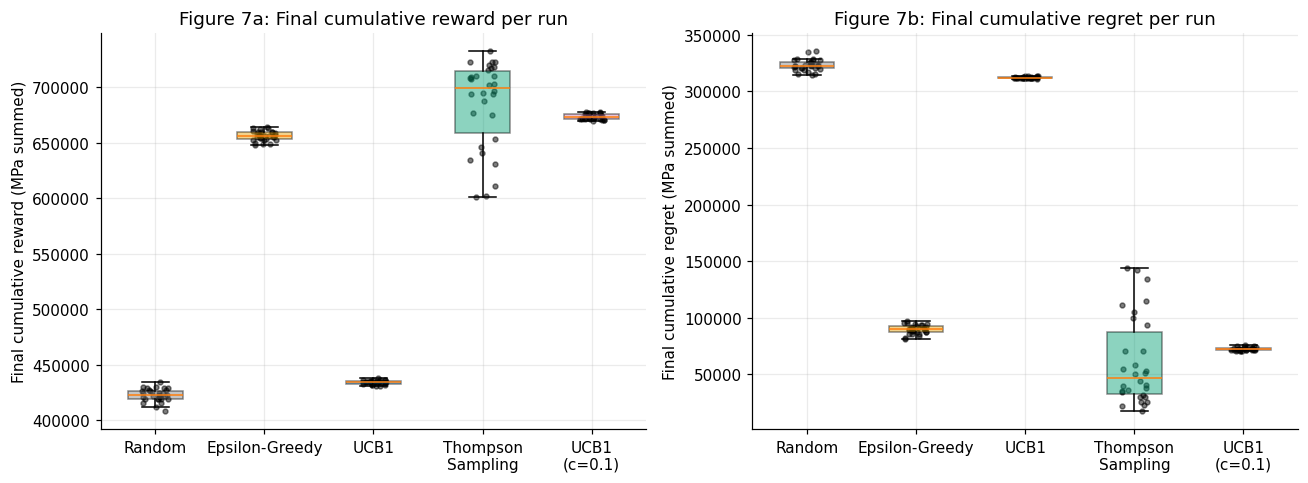

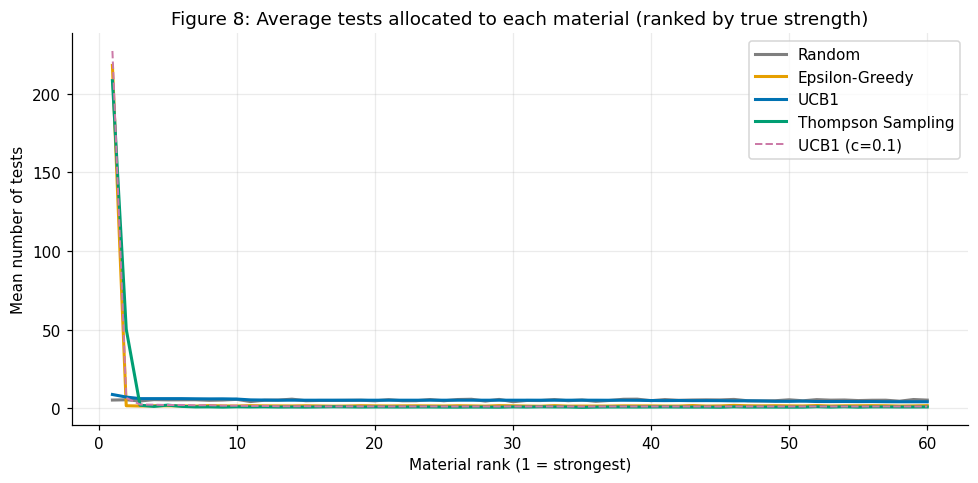

In [ ]:
x = np.arange(1, T + 1)
def band(ax, name, key, scale=1.0):
    a = stack(name, key) * scale
    m, c = a.mean(0), ci95(a)
    lw = 2.2 if name in CORE else 1.4
    ax.plot(x, m, color=COLORS[name], lw=lw, ls="-" if name in CORE else "--", label=name)
    ax.fill_between(x, m - c, m + c, color=COLORS[name], alpha=0.15)

# Figure 2: cumulative reward
fig, ax = plt.subplots(figsize=(8, 4.5))
for n in ALGOS: band(ax, n, "cum_reward")
ax.set(title="Figure 2: Cumulative observed reward", xlabel="Experiment number (test)",
       ylabel="Cumulative reward (MPa summed over tests)"); ax.legend()
plt.tight_layout(); plt.savefig("results/fig2_cumulative_reward.png", dpi=150); plt.show()

# Figure 3: average reward per experiment
fig, ax = plt.subplots(figsize=(8, 4.5))
for n in ALGOS: band(ax, n, "avg_reward")
ax.axhline(mu_star, color="k", ls=":", lw=1, label="Best material (true)")
ax.set(title="Figure 3: Average observed reward per experiment (learning curve)",
       xlabel="Experiment number (test)", ylabel="Average reward (MPa)"); ax.legend(loc="lower right")
plt.tight_layout(); plt.savefig("results/fig3_avg_reward.png", dpi=150); plt.show()

# Figure 4: regret
fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))
for n in ALGOS: band(axs[0], n, "simple_regret")
axs[0].set(title="Figure 4a: Simple regret of recommended material", xlabel="Experiment number (test)",
           ylabel="Simple regret (MPa)"); axs[0].legend()
for n in ALGOS: band(axs[1], n, "cum_regret")
axs[1].set(title="Figure 4b: Cumulative regret", xlabel="Experiment number (test)",
           ylabel="Cumulative regret (MPa summed over tests)")
plt.tight_layout(); plt.savefig("results/fig4_regret.png", dpi=150); plt.show()

# Figure 5: exploration vs exploitation
fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))
w = 20
for n in ALGOS:
    g = stack(n, "greedy").mean(0)
    sm = np.convolve(g, np.ones(w) / w, mode="valid")
    axs[0].plot(np.arange(w, T + 1), 100 * sm, color=COLORS[n], lw=2 if n in CORE else 1.3,
                ls="-" if n in CORE else "--", label=n)
axs[0].set(title=f"Figure 5a: Exploitation share ({w}-test moving average)", xlabel="Experiment number (test)",
           ylabel="Tests matching the greedy choice (%)"); axs[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3, frameon=False)
for n in ALGOS: band(axs[1], n, "unique_arms")
axs[1].axhline(K, color="k", ls=":", lw=1)
axs[1].set(title="Figure 5b: Distinct materials tested (breadth of exploration)",
           xlabel="Experiment number (test)", ylabel="Number of distinct materials tested")
plt.tight_layout(); plt.savefig("results/fig5_exploration_exploitation.png", dpi=150); plt.show()

# Figure 6: best material discovery
fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))
for n in ALGOS:
    axs[0].plot(x, 100 * stack(n, "best_found").mean(0), color=COLORS[n], lw=2 if n in CORE else 1.3,
                ls="-" if n in CORE else "--", label=n)
    axs[1].plot(x, 100 * stack(n, "top_discovered").mean(0), color=COLORS[n], lw=2 if n in CORE else 1.3,
                ls="-" if n in CORE else "--", label=n)
axs[0].set(title="Figure 6a: Best material correctly identified", xlabel="Experiment number (test)",
           ylabel="Runs where recommendation = true best (%)"); axs[0].legend()
axs[1].set(title=f"Figure 6b: Top-{int(CONFIG['TOP_FRAC']*100)}% material discovered", xlabel="Experiment number (test)",
           ylabel="Runs that have tested a top-10% material (%)")
plt.tight_layout(); plt.savefig("results/fig6_discovery.png", dpi=150); plt.show()

# Figure 7: spread across independent runs
fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))
names = list(ALGOS)
for ax, key, yl, ttl in [(axs[0], "cum_reward", "Final cumulative reward (MPa summed)", "Figure 7a: Final cumulative reward per run"),
                         (axs[1], "cum_regret", "Final cumulative regret (MPa summed)", "Figure 7b: Final cumulative regret per run")]:
    data = [stack(n, key)[:, -1] for n in names]
    bp = ax.boxplot(data, patch_artist=True, showfliers=False)
    ax.set_xticks(range(1, len(names) + 1)); ax.set_xticklabels([n.replace(" ", "\n") for n in names])
    for patch, n in zip(bp["boxes"], names): patch.set_facecolor(COLORS[n]); patch.set_alpha(0.45)
    rng_j = np.random.default_rng(0)
    for i, d in enumerate(data, 1): ax.scatter(i + rng_j.uniform(-0.12, 0.12, len(d)), d, s=10, color="k", alpha=0.5)
    ax.set(title=ttl, ylabel=yl)
plt.tight_layout(); plt.savefig("results/fig7_across_runs.png", dpi=150); plt.show()

# Figure 8 (extra): where the budget went
fig, ax = plt.subplots(figsize=(9, 4.5))
order = np.argsort(-mu)
for n in ALGOS:
    cnt = np.mean([r["counts"] for r in RUNS[n]], axis=0)[order]
    ax.plot(np.arange(1, K + 1), cnt, color=COLORS[n], lw=2 if n in CORE else 1.3,
            ls="-" if n in CORE else "--", label=n)
ax.set(title="Figure 8: Average tests allocated to each material (ranked by true strength)",
       xlabel="Material rank (1 = strongest)", ylabel="Mean number of tests"); ax.legend()
plt.tight_layout(); plt.savefig("results/fig8_allocation.png", dpi=150); plt.show()

## 16. Results and observations

### 16.1 Sanity checks
Each check asserts expected behaviour. If any fails, the notebook stops with an error.

In [ ]:
# 1. Equal budgets: every run used exactly T tests
for n in ALGOS:
    assert all(len(r["arms"]) == T and r["counts"].sum() == T for r in RUNS[n]), n
# 2. Random baseline is (near) uniform over arms
pulls = np.sum([r["counts"] for r in RUNS["Random"]], axis=0)
assert pulls.max() / pulls.mean() < 1.5 and pulls.min() / pulls.mean() > 0.6, "Random not uniform"
# 3. UCB1 and Epsilon-Greedy test every arm at least once (initial pass)
for n in ["UCB1", "UCB1 (c=0.1)", "Epsilon-Greedy"]:
    assert all((r["counts"] > 0).all() for r in RUNS[n]), n
# 4. Regret is non-negative and observed rewards differ from true means (noise present, no leakage)
for n in ALGOS:
    assert all(e["cum_regret"][-1] >= 0 and (e["simple_regret"] >= -1e-9).all() for e in EV[n]), n
r0 = RUNS["Random"][0]; assert np.abs(r0["rew"] - mu[r0["arms"]]).mean() > 1.0, "rewards look noiseless"
# 5. Noise level matches the configured SD
resid = np.concatenate([r["rew"] - mu[r["arms"]] for r in RUNS["Random"]])
assert abs(resid.std() - CONFIG["NOISE_SD"]) < 0.05 * CONFIG["NOISE_SD"], resid.std()
# 6. No leakage: agents hold no reference to the hidden means and were built from hyperparameters only
ag = ALGOS["Thompson Sampling"](np.random.default_rng(0))
assert not any(isinstance(v, np.ndarray) and v.shape == mu.shape and np.allclose(v, mu) for v in vars(ag).values())
# 7. Reproducibility: re-running a seed gives identical decisions
a1, a2 = run_one("Thompson Sampling", 3), run_one("Thompson Sampling", 3)
assert (a1["arms"] == a2["arms"]).all() and np.allclose(a1["rew"], a2["rew"])
# 8. Learning algorithms beat Random on cumulative reward (paired, same noise)
for n in ["Epsilon-Greedy", "Thompson Sampling", "UCB1 (c=0.1)"]:
    assert stack(n, "cum_reward")[:, -1].mean() > stack("Random", "cum_reward")[:, -1].mean(), n
# 9. Thompson posterior check on a tiny example: posterior mean lies between prior mean and sample mean
tg = ThompsonAgent(3, np.random.default_rng(0), 1000., 500., 100.)
for r in (1500., 1520., 1480.): tg.update(0, r)
pm, _ = tg.posterior(); assert 1000 < pm[0] < 1500 and abs(pm[0] - 1500) < 25
print("All sanity checks passed.")

All sanity checks passed.


### 16.2 Observations
The text below is generated from the results above (not hand-written), so it always matches the numbers.

In [ ]:
def final(name, key): return stack(name, key)[:, -1].mean()
core_rank = sorted(CORE, key=lambda n: -final(n, "cum_reward"))
lines = [f"Data source: {POOL_LABEL}",
         f"Pool: {K} materials, budget {T} tests, noise SD {CONFIG['NOISE_SD']:.0f} MPa, {NS} seeds.",
         "Ranking of the four required algorithms by mean cumulative reward: " + " > ".join(core_rank) + ".",
         f"Oracle (always testing the best material) would earn about {T * mu_star:,.0f} MPa in total; "
         f"Random earns {final('Random','cum_reward'):,.0f}."]
for n in ALGOS:
    lines.append(f"{n}: cumulative regret {final(n,'cum_regret'):,.0f}, final simple regret {final(n,'simple_regret'):.1f} MPa, "
                 f"best-material ID {100*final(n,'best_found'):.0f}%, distinct materials tested {final(n,'unique_arms'):.1f}.")
lines.append("Median tests until a top-10% material is first tested: " +
             ", ".join(f"{n} {np.median([e['discovery_step'] for e in EV[n]]):.0f}" for n in ALGOS) + ".")
print("\n".join(lines))

# save everything the report and slides need
OUT = dict(config=CONFIG, pool_label=POOL_LABEL, K=K, T=T, n_seeds=NS, mu_star=float(mu_star),
           n_top=n_top, top_threshold=float(mu[top_set].min()), pool_mean=float(mu.mean()),
           summary=summary.reset_index().to_dict(orient="records"),
           paired={k: [float(v[0]), float(v[1])] for k, v in paired.items()},
           raw={n: dict(cum_reward=float(final(n, "cum_reward")), cum_regret=float(final(n, "cum_regret")),
                        simple_regret=float(final(n, "simple_regret")), best_id=float(final(n, "best_found")),
                        unique=float(final(n, "unique_arms")),
                        discovery_median=float(np.median([e["discovery_step"] for e in EV[n]]))) for n in ALGOS},
           observations=lines)
with open("results/results.json", "w") as f: json.dump(OUT, f, indent=2)
print("\nSaved results/results.json and figures in results/")

Data source: REAL: matminer steel_strength (experimental yield strength, MPa)
Pool: 60 materials, budget 300 tests, noise SD 100 MPa, 30 seeds.
Ranking of the four required algorithms by mean cumulative reward: Thompson Sampling > Epsilon-Greedy > UCB1 > Random.
Oracle (always testing the best material) would earn about 746,190 MPa in total; Random earns 422,827.
Random: cumulative regret 323,156, final simple regret 0.0 MPa, best-material ID 100%, distinct materials tested 59.6.
Epsilon-Greedy: cumulative regret 89,898, final simple regret 0.0 MPa, best-material ID 100%, distinct materials tested 60.0.
UCB1: cumulative regret 312,026, final simple regret 0.0 MPa, best-material ID 100%, distinct materials tested 60.0.
Thompson Sampling: cumulative regret 60,954, final simple regret 22.0 MPa, best-material ID 93%, distinct materials tested 39.5.
UCB1 (c=0.1): cumulative regret 72,594, final simple regret 0.0 MPa, best-material ID 100%, distinct materials tested 60.0.
Median tests until 

## 17. Limitations and ethics

**Limitations**
- Measurement noise is **simulated**. Real reported strengths are treated as exact hidden means, and the dataset has no replicate measurements, so the noise level is an assumption.
- Only 60 of the 312 steels are used, with one pool seed, budget and noise setting.
- Noise is assumed Gaussian, equal for all arms, and known to Thompson Sampling. Real measurements can be heteroscedastic, biased, or heavy-tailed. The Thompson prior (mean 1000 MPa) is not matched to the pool, and rewards above 2500 MPa are clipped for UCB1.
- Each arm is treated independently. With real compositions, similar alloys have similar properties, which a contextual bandit could exploit (not implemented).
- Single objective (yield strength). Real alloy choice also weighs cost, ductility, corrosion and manufacturability.
- Repeatedly testing the same alloy is assumed possible and informative; physical specimens are consumed.
- UCB1 and Epsilon-Greedy hyperparameters are not tuned (except the labelled UCB1 $c=0.1$ sensitivity variant).

**Ethical considerations**
- **Honesty about data:** simulated numbers must never be presented as measurements of real materials.
- **Over-trust risk:** a bandit's recommendation is a screening aid. Safety-critical materials (structures, medical, aerospace) need standards-compliant validation.
- **Bias in public datasets:** literature-compiled data over-represents well-studied systems, so screening may keep favouring familiar alloys.
- **Resource and environmental cost:** fewer experiments save material, energy and time, which is a benefit, but optimising one property can hide downsides such as toxic or scarce elements.
- **Human oversight:** domain experts should review the candidates the algorithm favours before committing budget.

In [ ]:
checklist = {"Data source": POOL_LABEL,
             "Observed vs true reward separated": "yes (env hides mu; evaluator uses mu)",
             "Equal budget for all algorithms": f"{T} tests each",
             "Fixed seeds": f"pool seed {CONFIG['POOL_SEED']}, run seeds 0..{NS-1}",
             "Leakage check": "passed (Section 16.1)"}
for k, v in checklist.items(): print(f"{k:38s}{v}")

Data source                           REAL: matminer steel_strength (experimental yield strength, MPa)
Observed vs true reward separated     yes (env hides mu; evaluator uses mu)
Equal budget for all algorithms       300 tests each
Fixed seeds                           pool seed 42, run seeds 0..29
Leakage check                         passed (Section 16.1)


## 18. Final conclusion

Bandit algorithms let a researcher spend a limited testing budget on promising materials instead of sampling uniformly. In this simulation, algorithms that use their past measurements gather more reward and lower regret than random selection, and the differences between them reflect how each handles the exploration-exploitation trade-off: Epsilon-Greedy explores at a constant rate, UCB1 explores by uncertainty bonus (strongly dependent on its scale parameter), and Thompson Sampling explores through posterior sampling. The exact ranking and numbers are printed in Section 16.2 and saved in `results/results.json`.

Everything runs from this single notebook, with fixed seeds, equal budgets, no information leakage, and an explicit label of what is real data and what is simulated.

In [ ]:
print("Project 5 complete: Bandit-Based Material Screening")
print("Best algorithm by cumulative reward among the four required:",
      max(CORE, key=lambda n: final(n, "cum_reward")))
print("Outputs: results/results.json and results/fig*.png")
import shutil; shutil.make_archive("results", "zip", "results"); print("Also zipped as results.zip")

Project 5 complete: Bandit-Based Material Screening
Best algorithm by cumulative reward among the four required: Thompson Sampling
Outputs: results/results.json and results/fig*.png
Also zipped as results.zip
